# Module 5 Lab: Honest Charts and a T-Test

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This project takes a few datasets and turns them into clear, labeled charts, then uses a t-test to check if the difference between two chick feeds is real or just luck.

## Setup

First I imported everything and printed the seaborn and scipy versions to make sure both packages installed right.

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
from scipy.stats import ttest_ind

sns.set_theme(style='whitegrid')

print('seaborn', sns.__version__)
print('scipy  ', scipy.__version__)

seaborn 0.13.2
scipy   1.18.1


## Step 1: Group means for chick feeds

In [39]:
chicks = pd.read_csv('chickwts.csv', index_col=0)
print(chicks.shape)   # 71 chicks, 2 columns

feed_means = chicks.groupby('feed')['weight'].mean().sort_values()
feed_means.round(1)

(71, 2)


feed
horsebean    160.2
linseed      218.8
soybean      246.4
meatmeal     276.9
casein       323.6
sunflower    328.9
Name: weight, dtype: float64

I grouped the chicks by feed and took the mean weight for each one. Horsebean came out lowest at about 160 g. 


## Step 2: Sorted bar chart

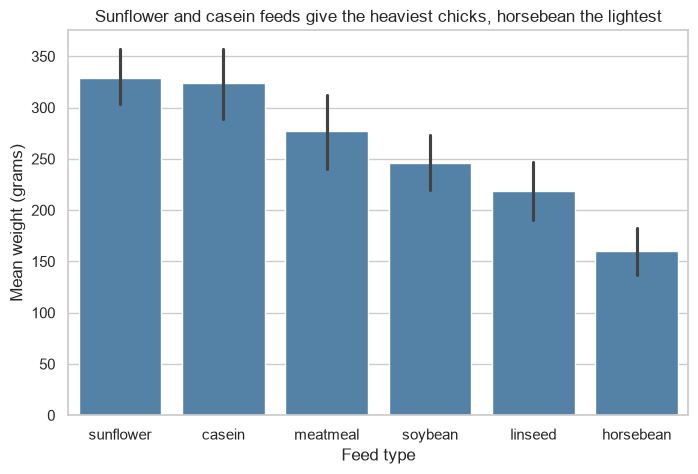

In [40]:
order = feed_means.sort_values(ascending=False).index   # sort so the heaviest feed is first

plt.figure(figsize=(8, 5))
sns.barplot(data=chicks, x='feed', y='weight', order=order, color='steelblue')
plt.title('Sunflower and casein feeds give the heaviest chicks, horsebean the lightest')
plt.xlabel('Feed type')
plt.ylabel('Mean weight (grams)')
plt.show()

I sorted the bars from heaviest to lightest so the ranking is easy to read. The black lines on top are seaborn's default error bars (95% confidence intervals).

## Step 3: Histogram of all weights

mean = 261.3 g   median = 258.0 g


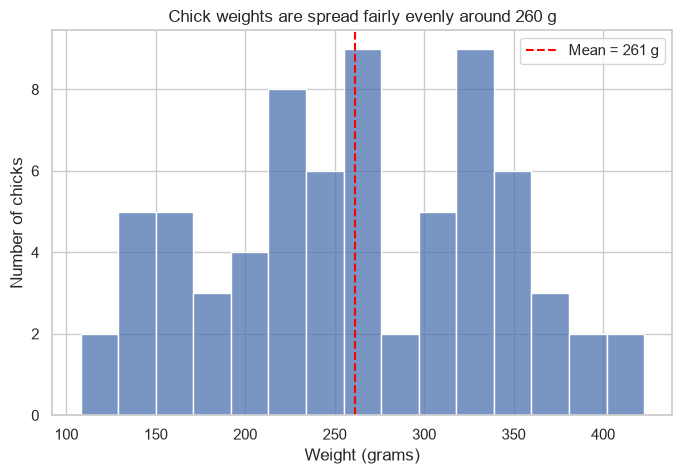

In [41]:
mean_wt = chicks['weight'].mean()
print(f"mean = {mean_wt:.1f} g   median = {chicks['weight'].median():.1f} g")

plt.figure(figsize=(8, 5))
sns.histplot(data=chicks, x='weight', bins=15)
plt.axvline(mean_wt, color='red', linestyle='--', label=f'Mean = {mean_wt:.0f} g')
plt.title('Chick weights are spread fairly evenly around 260 g')
plt.xlabel('Weight (grams)')
plt.ylabel('Number of chicks')
plt.legend()
plt.show()

To read the histogram I also printed the mean and median. They're close (261 g and 258 g), which matches the shape: roughly symmetric around 260 g with no big skew. The weights are spread wide, from about 108 g to 423 g, because the feeds give such different results.

## Step 4: Line chart of museum visitors

In [42]:
museums = pd.read_csv('museum_visitors.csv', parse_dates=['Date'])
print(museums.shape)
museums.head()

(59, 5)


,Date,Avila Adobe,Firehouse Museum,Chinese American Museum,America Tropical Interpretive Center
0,2014-01-01,24778,4486,1581,6602
1,2014-02-01,18976,4172,1785,5029
2,2014-03-01,25231,7082,3229,8129
3,2014-04-01,26989,6756,2129,2824
4,2014-05-01,36883,10858,3676,10694


The museum file has a separate column for each museum. To get one line per museum, I used `melt` to stack them into a single `Visitors` column with a `Museum` label, then passed `Museum` to `hue`.

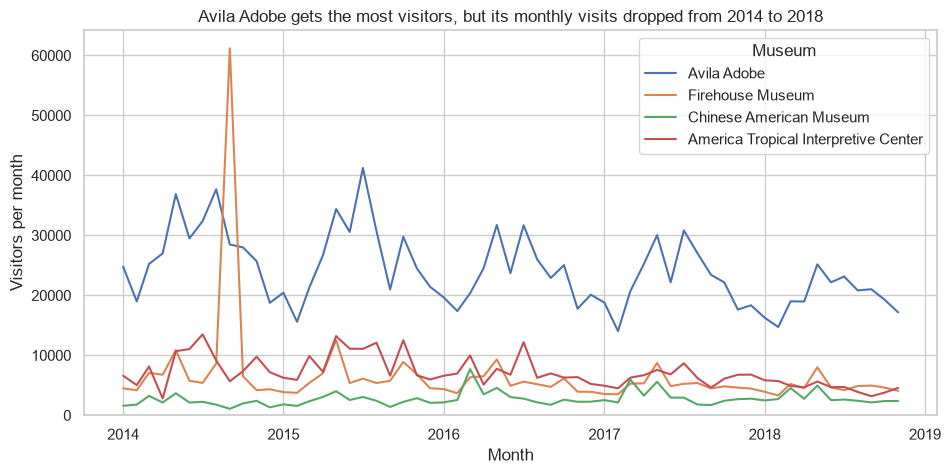

In [43]:
visits = museums.melt(id_vars='Date', var_name='Museum', value_name='Visitors')

plt.figure(figsize=(11, 5))
sns.lineplot(data=visits, x='Date', y='Visitors', hue='Museum')
plt.title('Avila Adobe gets the most visitors, but its monthly visits dropped from 2014 to 2018')
plt.xlabel('Month')
plt.ylabel('Visitors per month')
plt.ylim(bottom=0)
plt.show()

**Trend:** Avila Adobe's visitors go down over the years, from around 25k to 40k a month in 2014 to about 17k to 25k in 2018, and they peak every summer and dip every winter.

The big spike is Firehouse Museum in September 2014 (61,192 visitors).

## Step 5: Scatter and heatmap on my sales data

In [44]:
sales = pd.read_csv('sales_clean.csv')
sales['revenue'] = sales['price'] * sales['qty']   # same revenue column I made in Module 4
print(sales.shape)   # 292 rows, 8 columns

(292, 8)


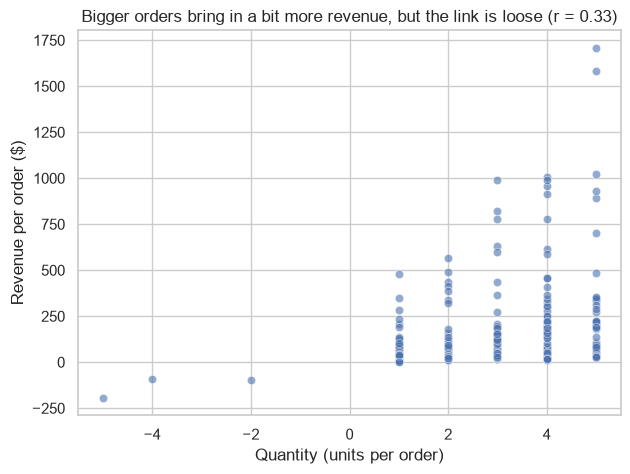

In [45]:
r = sales['qty'].corr(sales['revenue'])

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sales, x='qty', y='revenue', alpha=0.6)
plt.title(f'Bigger orders bring in a bit more revenue, but the link is loose (r = {r:.2f})')
plt.xlabel('Quantity (units per order)')
plt.ylabel('Revenue per order ($)')
plt.show()

I rebuilt the same `revenue` column from Module 4 (price × qty). 

For the heatmap I picked the same three columns I used in Lab 4. 

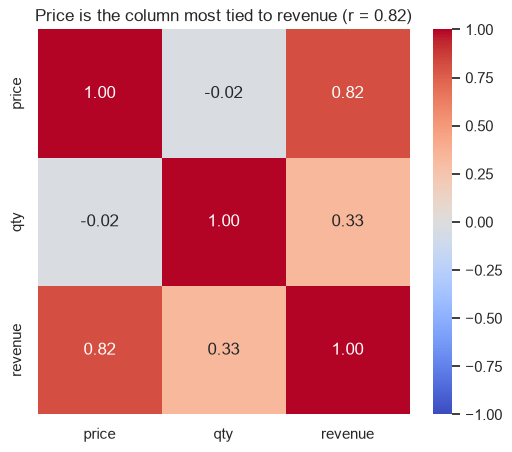

In [46]:
plt.figure(figsize=(6, 5))
sns.heatmap(sales[['price', 'qty', 'revenue']].corr(numeric_only=True),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Price is the column most tied to revenue (r = 0.82)')
plt.show()

**Strongest off-diagonal correlation:** `price` vs `revenue` at r = 0.82, which matches what I got in Lab 4.

## Step 6: The hypothesis

I'm comparing casein-fed and horsebean-fed chicks.

**Null hypothesis (H0):** Casein and horsebean chicks have the same average weight, and the gap in my sample is just random chance.

**Alternative (H1):** The two feeds give different average weights.

## Step 7: Run the t-test

In [47]:
casein = chicks[chicks['feed'] == 'casein']['weight']
horsebean = chicks[chicks['feed'] == 'horsebean']['weight']

print(f'casein:    n = {len(casein)}, mean = {casein.mean():.1f} g')
print(f'horsebean: n = {len(horsebean)}, mean = {horsebean.mean():.1f} g')

result = ttest_ind(casein, horsebean)


casein:    n = 12, mean = 323.6 g
horsebean: n = 10, mean = 160.2 g


In [48]:
diff = casein.mean() - horsebean.mean()
print(f'Difference in means: {diff:.1f} g')
print(f't = {result.statistic:.2f}')
print(f'p = {result.pvalue:.7f}')

Difference in means: 163.4 g
t = 7.02
p = 0.0000008


I pulled out each feed's weights with a filter, checked that both groups had data, and ran `ttest_ind`. t came out around 7, which means the gap between the means is about 7 times bigger than the normal noise in the data. 

The p-value is way below 0.05.

In [49]:
ci = result.confidence_interval(confidence_level=0.95)
print(f'95% CI for the difference: {ci.low:.1f} g to {ci.high:.1f} g')

95% CI for the difference: 114.8 g to 211.9 g


## Step 8: Conclusion

Casein-fed chicks weighed about **163 g more** than horsebean-fed chicks on average (323.6 g vs 160.2 g, t = 7.02, **p ≈ 0.0000008**), so I reject the null hypothesis and conclude casein does produce heavier chicks. However, this is only 12 vs 10 chicks from one experiment, so more data is needed to conclude that it applies to every chick. 

## Step 9: Honest-chart audit

I picked my bar chart from Step 2.

1. **Zero baseline.** I kept the y-axis starting at 0 g so the bar heights compare fairly. 
2. **Units and one color.** I labeled the y-axis "Mean weight (grams)" so it's clear what the numbers are, and I used the same color for every bar so color doesn't suggest a difference that isn't in the data.

## AI Use

I used AI to help with syntax and refine wording on this lab.